# Pairwise Mantel tests among three phylogenetic trees

This notebook compares all pairwise combinations of `Domain_tree.nwk`,
`FL_tree.nwk`, and `non_DBD_tree.nwk`. Spearman is treated as the primary
analysis, and its three pairwise permutation p-values are adjusted together
with the Holm method. Pearson results are retained as unadjusted sensitivity
analyses.


In [1]:
# ---- 1) Install and import dependencies ----
!pip -q install biopython pandas numpy scipy scikit-bio matplotlib statsmodels

from pathlib import Path
from itertools import combinations

import numpy as np
import pandas as pd
from Bio import Phylo
from scipy.spatial.distance import squareform
from skbio.stats.distance import DistanceMatrix, mantel
from statsmodels.stats.multitest import multipletests
import matplotlib.pyplot as plt


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.2/3.2 MB 7.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.9/10.9 MB 34.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.1/79.1 kB 2.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.3/12.3 MB 35.8 MB/s eta 0:00:00


In [2]:
# ---- 2) Configure input trees and output directory ----
tree_paths = {
    "Domain": Path("Domain_tree.nwk"),
    "FL": Path("FL_tree.nwk"),
    "non_DBD": Path("non_DBD_tree.nwk"),
}

output_dir = Path("260826_Mantel_pairwise_outputs")
output_dir.mkdir(exist_ok=True)

missing = [str(path) for path in tree_paths.values() if not path.exists()]
if missing:
    raise FileNotFoundError("Missing Newick file(s):\n" + "\n".join(missing))

print("Input trees:")
for name, path in tree_paths.items():
    print(f"  {name}: {path}")
print(f"\nOutput directory: {output_dir.resolve()}")


Input trees:
  Domain: Domain_tree.nwk
  FL: FL_tree.nwk
  non_DBD: non_DBD_tree.nwk

Output directory: /content/260826_Mantel_pairwise_outputs


In [3]:
# ---- 3) Read trees, collect tips, and define helper functions ----
trees = {name: Phylo.read(path, "newick") for name, path in tree_paths.items()}

def tip_names(tree):
    return sorted([t.name for t in tree.get_terminals() if t.name is not None])

tips_by_tree = {name: set(tip_names(tree)) for name, tree in trees.items()}

print("Tip counts:")
for name, tips in tips_by_tree.items():
    print(f"  {name}: {len(tips)}")

print("\nShared tips for each pair:")
for name_a, name_b in combinations(trees, 2):
    common = sorted(tips_by_tree[name_a] & tips_by_tree[name_b])
    print(f"  {name_a} vs {name_b}: {len(common)}")
    assert len(common) >= 3, f"Need at least 3 shared taxa for {name_a} vs {name_b}."

def safe_name(name):
    return name.replace("/", "_").replace(" ", "_")

def patristic_matrix(tree, taxa):
    """Compute patristic distances between all pairs of tips in taxa."""
    n = len(taxa)
    matrix = np.zeros((n, n), dtype=float)
    for i in range(n):
        for j in range(i + 1, n):
            distance = tree.distance(taxa[i], taxa[j])
            matrix[i, j] = distance
            matrix[j, i] = distance
    return matrix

def summarize_mat(name, matrix):
    off_diag = ~np.eye(matrix.shape[0], dtype=bool)
    positive = matrix[matrix > 0]
    min_value = np.min(positive) if positive.size else 0
    median_value = np.median(positive) if positive.size else 0
    zero_offdiag = int(np.sum((matrix == 0) & off_diag))
    print(
        f"{name}: min={min_value:.4g}, median={median_value:.4g}, "
        f"max={np.max(matrix):.4g}, zeros(offdiag)={zero_offdiag}"
    )

def save_distance_matrix(name, matrix, taxa):
    path = output_dir / f"{name}_patristic_distances.tsv"
    pd.DataFrame(matrix, index=taxa, columns=taxa).to_csv(path, sep="\t")
    return path

def save_scatter_plot(pair_label, matrix_a, matrix_b, label_a, label_b):
    vec_a = squareform(matrix_a, checks=False)
    vec_b = squareform(matrix_b, checks=False)
    fig, ax = plt.subplots(figsize=(6, 6))
    ax.scatter(vec_a, vec_b, s=10, alpha=0.7)
    ax.set_xlabel(f"{label_a} patristic distance")
    ax.set_ylabel(f"{label_b} patristic distance")
    ax.set_title(f"Pairwise distances: {label_a} vs {label_b}")
    fig.tight_layout()
    path = output_dir / f"{pair_label}_pairwise_distances_scatter.png"
    fig.savefig(path, dpi=300)
    plt.show()
    return path


Tip counts:
  Domain: 234
  FL: 233
  non_DBD: 233

Shared tips for each pair:
  Domain vs FL: 233
  Domain vs non_DBD: 233
  FL vs non_DBD: 233


Pair: Domain vs FL
Common taxa: 233
Domain distances: min=0.09311, median=2.904, max=6.079, zeros(offdiag)=0
FL distances: min=0.2838, median=3.842, max=5.868, zeros(offdiag)=0


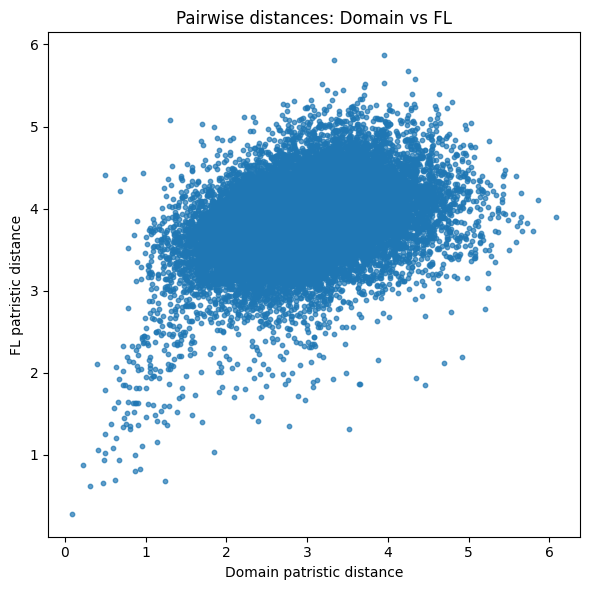

Unadjusted Mantel test results:
  Spearman r = 0.3652120131257616
  Spearman p = 0.0001
  Pearson  r = 0.3854067702279458
  Pearson  p = 0.0001
Pair: Domain vs non_DBD
Common taxa: 233
Domain distances: min=0.09311, median=2.904, max=6.079, zeros(offdiag)=0
non_DBD distances: min=0.2788, median=4.204, max=8.055, zeros(offdiag)=0


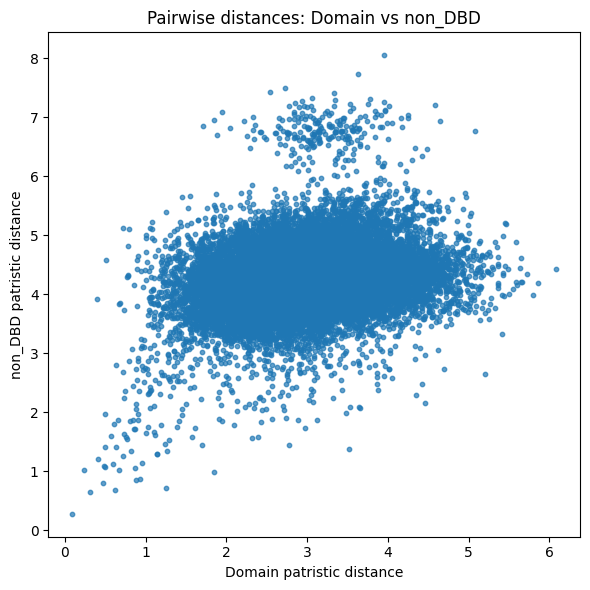

Unadjusted Mantel test results:
  Spearman r = 0.23773191778436098
  Spearman p = 0.0001
  Pearson  r = 0.24573736113057004
  Pearson  p = 0.0001
Pair: FL vs non_DBD
Common taxa: 233
FL distances: min=0.2838, median=3.842, max=5.868, zeros(offdiag)=0
non_DBD distances: min=0.2788, median=4.204, max=8.055, zeros(offdiag)=0


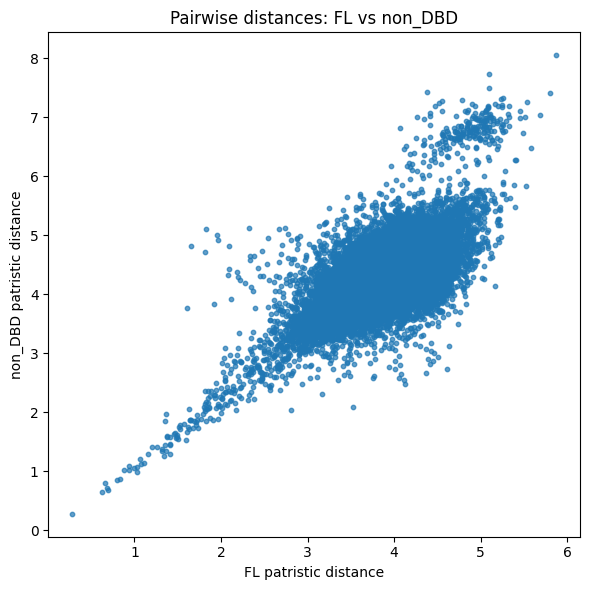

Unadjusted Mantel test results:
  Spearman r = 0.5770696642425288
  Spearman p = 0.0001
  Pearson  r = 0.6597599876202487
  Pearson  p = 0.0001
Spearman Mantel tests with Holm correction (family size = 3):
tree_1  tree_2  spearman_r  spearman_p  spearman_p_holm  spearman_significant_holm_0.05
Domain      FL    0.365212      0.0001           0.0003                            True
Domain non_DBD    0.237732      0.0001           0.0003                            True
    FL non_DBD    0.577070      0.0001           0.0003                            True
Saved summary: 260826_Mantel_pairwise_outputs/pairwise_mantel_results.tsv


,tree_1,tree_2,common_taxa,permutations,alternative,spearman_r,spearman_p,spearman_p_holm,spearman_significant_holm_0.05,spearman_holm_family_size,pearson_r,pearson_p,common_taxa_file,tree_1_distance_matrix,tree_2_distance_matrix,scatter_plot
0,Domain,FL,233,9999,two-sided,0.365212,0.0001,0.0003,True,3,0.385407,0.0001,260826_Mantel_pairwise_outputs/Domain_vs_FL_co...,260826_Mantel_pairwise_outputs/Domain_vs_FL_Do...,260826_Mantel_pairwise_outputs/Domain_vs_FL_FL...,260826_Mantel_pairwise_outputs/Domain_vs_FL_pa...
1,Domain,non_DBD,233,9999,two-sided,0.237732,0.0001,0.0003,True,3,0.245737,0.0001,260826_Mantel_pairwise_outputs/Domain_vs_non_D...,260826_Mantel_pairwise_outputs/Domain_vs_non_D...,260826_Mantel_pairwise_outputs/Domain_vs_non_D...,260826_Mantel_pairwise_outputs/Domain_vs_non_D...
2,FL,non_DBD,233,9999,two-sided,0.577070,0.0001,0.0003,True,3,0.659760,0.0001,260826_Mantel_pairwise_outputs/FL_vs_non_DBD_c...,260826_Mantel_pairwise_outputs/FL_vs_non_DBD_F...,260826_Mantel_pairwise_outputs/FL_vs_non_DBD_n...,260826_Mantel_pairwise_outputs/FL_vs_non_DBD_p...


In [4]:
# ---- 4) Run all pairwise Mantel tests ----
permutations = 9999
alternative = "two-sided"
results = []

for name_a, name_b in combinations(trees, 2):
    pair_label = f"{safe_name(name_a)}_vs_{safe_name(name_b)}"
    print("=" * 72)
    print(f"Pair: {name_a} vs {name_b}")

    common = sorted(tips_by_tree[name_a] & tips_by_tree[name_b])
    print(f"Common taxa: {len(common)}")
    common_taxa_path = output_dir / f"{pair_label}_common_taxa.txt"
    common_taxa_path.write_text("\n".join(common) + "\n")

    matrix_a = patristic_matrix(trees[name_a], common)
    matrix_b = patristic_matrix(trees[name_b], common)
    summarize_mat(f"{name_a} distances", matrix_a)
    summarize_mat(f"{name_b} distances", matrix_b)

    dm_a = DistanceMatrix(matrix_a, ids=common)
    dm_b = DistanceMatrix(matrix_b, ids=common)

    spearman_r, spearman_p, n_taxa = mantel(
        dm_a, dm_b, method="spearman", permutations=permutations,
        alternative=alternative,
    )
    pearson_r, pearson_p, _ = mantel(
        dm_a, dm_b, method="pearson", permutations=permutations,
        alternative=alternative,
    )

    matrix_a_path = save_distance_matrix(
        f"{pair_label}_{safe_name(name_a)}", matrix_a, common
    )
    matrix_b_path = save_distance_matrix(
        f"{pair_label}_{safe_name(name_b)}", matrix_b, common
    )
    scatter_path = save_scatter_plot(
        pair_label, matrix_a, matrix_b, name_a, name_b
    )

    results.append({
        "tree_1": name_a,
        "tree_2": name_b,
        "common_taxa": n_taxa,
        "permutations": permutations,
        "alternative": alternative,
        "spearman_r": spearman_r,
        "spearman_p": spearman_p,
        "pearson_r": pearson_r,
        "pearson_p": pearson_p,
        "common_taxa_file": str(common_taxa_path),
        "tree_1_distance_matrix": str(matrix_a_path),
        "tree_2_distance_matrix": str(matrix_b_path),
        "scatter_plot": str(scatter_path),
    })

    print("Unadjusted Mantel test results:")
    print(f"  Spearman r = {spearman_r}")
    print(f"  Spearman p = {spearman_p}")
    print(f"  Pearson  r = {pearson_r}")
    print(f"  Pearson  p = {pearson_p}")

results_df = pd.DataFrame(results)

# Holm correction across the three primary Spearman tests
holm_alpha = 0.05
spearman_reject_holm, spearman_p_holm, _, _ = multipletests(
    results_df["spearman_p"].to_numpy(),
    alpha=holm_alpha,
    method="holm",
)
results_df["spearman_p_holm"] = spearman_p_holm
results_df["spearman_significant_holm_0.05"] = spearman_reject_holm
results_df["spearman_holm_family_size"] = len(results_df)

preferred_columns = [
    "tree_1", "tree_2", "common_taxa", "permutations", "alternative",
    "spearman_r", "spearman_p", "spearman_p_holm",
    "spearman_significant_holm_0.05", "spearman_holm_family_size",
    "pearson_r", "pearson_p",
]
remaining_columns = [c for c in results_df.columns if c not in preferred_columns]
results_df = results_df[preferred_columns + remaining_columns]

results_path = output_dir / "pairwise_mantel_results.tsv"
results_df.to_csv(results_path, sep="\t", index=False)

print("=" * 72)
print("Spearman Mantel tests with Holm correction (family size = 3):")
print(results_df[[
    "tree_1", "tree_2", "spearman_r", "spearman_p",
    "spearman_p_holm", "spearman_significant_holm_0.05",
]].to_string(index=False))
print(f"Saved summary: {results_path}")
results_df


In [5]:
# ---- 5) Optional: zip outputs for download or sharing ----
import zipfile

zip_path = Path("Mantel_pairwise_outputs_Spearman_Holm.zip")
with zipfile.ZipFile(zip_path, "w", compression=zipfile.ZIP_DEFLATED) as zf:
    for path in output_dir.rglob("*"):
        if path.is_file():
            zf.write(path, arcname=path.relative_to(output_dir.parent))

print(f"Created: {zip_path.resolve()}")

# In Google Colab, uncomment:
# from google.colab import files
# files.download(str(zip_path))


Created: /content/Mantel_pairwise_outputs_Spearman_Holm.zip
